# Price–Volume Signal Research — Master Notebook
### Detection of Short-Term Trading Inefficiencies Using Price–Volume Proxy Signals

This is the **single consolidated notebook** — everything from the three earlier
versions, merged, with nothing dropped and the one real gap (Midcap 150 never got
the rigorous walk-forward + baseline treatment, only a quick Sharpe comparison)
now fixed. Every analysis below runs **identically on both Nifty 50 and Nifty
Midcap 150**, side by side.

**What's included, and where it came from:**

| Section | Content | Origin |
|---|---|---|
| 2–5 | Config, universe fetch, features, leakage checklist | v1 + Ryan's fix |
| 6–7 | Backtest engine, panel construction (both universes) | v1 + v2 |
| 8 | Ablation study (AV/PP/VS, all combos) — **both universes** | v2, extended |
| 9 | Weighted linear signal search — **both universes** | v2, extended |
| 10 | Transaction costs, gross vs net — **both universes** | v2, extended |
| 11 | Holding-period sensitivity (1/3/5-day) — **both universes** | v2, extended |
| 12 | Walk-forward evaluation + baselines — **both universes** | v3, extended to Midcap |
| 13 | Consolidated verdict, write-up guidance | v3 |

**Terminology note (Ryan's point):** built entirely from Yahoo Finance OHLCV —
no order-book, spread, or trade-level data. This is **price–volume proxy
signals for short-term trading activity**, not order-flow microstructure in the
strict sense — the write-up should say this explicitly.

**Runtime warning:** this notebook downloads and fully re-analyzes ~200 tickers
across two universes, including a 6-fold walk-forward with an in-fold weight
search. Expect this to take several minutes end-to-end on Colab — it is not stuck.

## 1. Setup

In [ ]:
!pip install yfinance --quiet

In [ ]:
import io
import numpy as np
import pandas as pd
import requests
import yfinance as yf
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.style.use("seaborn-v0_8-darkgrid")


In [ ]:
# ---------------------------------------------------------------
# CONFIG
# ---------------------------------------------------------------
START_DATE = "2021-01-01"
END_DATE   = "2026-08-01"

AV_WINDOW   = 20
VS_WINDOW   = 20
ATR_WINDOW  = 14
MOM_WINDOW  = 20

HOLD_DAYS_LIST = [1, 3, 5]     # tested in Section 11
DEFAULT_HOLD   = 5             # frozen horizon for Sections 8-10, and the main claim in Section 12
COST_BPS       = 20            # 0.20% per trade, used everywhere for comparability

LONG_QUANTILE  = 0.8
SHORT_QUANTILE = 0.2

N_FOLDS = 6                    # walk-forward: fold 1 = training only, folds 2-6 = OOS tests

BENCHMARK = "^NSEI"

NIFTY50 = [
    "RELIANCE.NS", "TCS.NS", "HDFCBANK.NS", "ICICIBANK.NS", "INFY.NS",
    "HINDUNILVR.NS", "ITC.NS", "SBIN.NS", "BHARTIARTL.NS", "BAJFINANCE.NS",
    "KOTAKBANK.NS", "LT.NS", "AXISBANK.NS", "ASIANPAINT.NS", "MARUTI.NS",
    "TITAN.NS", "SUNPHARMA.NS", "ULTRACEMCO.NS", "NESTLEIND.NS", "WIPRO.NS",
    "M&M.NS", "NTPC.NS", "POWERGRID.NS", "ONGC.NS", "TATASTEEL.NS",
    "TATAMOTORS.NS", "ADANIENT.NS", "JSWSTEEL.NS", "HCLTECH.NS", "BAJAJFINSV.NS",
    "COALINDIA.NS", "INDUSINDBK.NS", "GRASIM.NS", "TECHM.NS", "DRREDDY.NS",
    "CIPLA.NS", "EICHERMOT.NS", "HEROMOTOCO.NS", "BRITANNIA.NS", "DIVISLAB.NS",
    "APOLLOHOSP.NS", "BPCL.NS", "SBILIFE.NS", "HDFCLIFE.NS", "BAJAJ-AUTO.NS",
    "UPL.NS", "TATACONSUM.NS", "ADANIPORTS.NS", "SHRIRAMFIN.NS", "HINDALCO.NS",
]


## 2. Universe Fetch — Nifty 50 (static) + Nifty Midcap 150 (live)

Nifty Midcap 150 constituents are fetched **live from NSE Indices' CSV** rather
than hardcoded — the index reconstitutes every March/September, so a typed-out
150-ticker list would silently go stale. If the fetch fails, it fails loudly —
check the printed error rather than assuming Section 8 onward used the right
universe.

In [ ]:
def fetch_index_constituents(url, symbol_col_candidates=("Symbol", "SYMBOL", "Symbol Name")):
    resp = requests.get(url, timeout=15, headers={"User-Agent": "Mozilla/5.0"})
    resp.raise_for_status()
    df = pd.read_csv(io.BytesIO(resp.content))
    col = next((c for c in df.columns if c.strip() in symbol_col_candidates), None)
    if col is None:
        raise ValueError(f"Could not find a symbol column among: {df.columns.tolist()}")
    return (df[col].astype(str).str.strip() + ".NS").tolist()

MIDCAP150_URL = "https://www.niftyindices.com/IndexConstituent/ind_niftymidcap150list.csv"

try:
    NIFTY_MIDCAP150 = fetch_index_constituents(MIDCAP150_URL)
    print(f"Fetched {len(NIFTY_MIDCAP150)} Nifty Midcap 150 constituents live from NSE Indices.")
except Exception as e:
    NIFTY_MIDCAP150 = []
    print("LIVE FETCH FAILED — Midcap sections will be skipped until this is fixed.")
    print("Error:", e)
    print("Fix: download the CSV manually from niftyindices.com -> Indices -> Nifty Midcap 150,")
    print("     then set NIFTY_MIDCAP150 = [...] yourself before re-running from Section 7.")

UNIVERSES = {"Nifty 50": NIFTY50}
if NIFTY_MIDCAP150:
    UNIVERSES["Nifty Midcap 150"] = NIFTY_MIDCAP150


Fetched 150 Nifty Midcap 150 constituents live from NSE Indices.


## 3. Reusable Pipeline — Download → Features → Cross-Sectional Panel

In [ ]:
def download_universe(tickers, start, end, min_obs=250, batch_size=100):
    data = {}
    for i in range(0, len(tickers), batch_size):
        batch = tickers[i:i + batch_size]
        raw = yf.download(batch, start=start, end=end, auto_adjust=False,
                           group_by="ticker", threads=True, progress=False)
        for t in batch:
            try:
                df = raw[t].dropna(how="all").copy() if len(batch) > 1 else raw.dropna(how="all").copy()
            except KeyError:
                continue
            df = df.rename(columns=str.title)
            df = df.dropna(subset=["Open", "High", "Low", "Close", "Volume"])
            if len(df) >= min_obs:
                data[t] = df
    print(f"  downloaded {len(data)}/{len(tickers)} tickers with sufficient history")
    return data


def compute_atr(df, window=ATR_WINDOW):
    high, low, close = df["High"], df["Low"], df["Close"]
    prev_close = close.shift(1)
    tr = pd.concat([high - low, (high - prev_close).abs(), (low - prev_close).abs()], axis=1).max(axis=1)
    return tr.rolling(window).mean()


def engineer_features(df, hold_days_list=HOLD_DAYS_LIST):
    out = df.copy()
    # --- every column below uses only data at or before the current row's date ---
    out["Ret1"]  = out["Close"].pct_change()
    out["AV"]    = out["Volume"] / out["Volume"].rolling(AV_WINDOW).mean()
    out["PP"]    = (out["Close"] - out["Open"]) / (out["High"] - out["Low"]).replace(0, np.nan)
    out["ATR"]   = compute_atr(out)
    out["VS"]    = out["ATR"] / out["ATR"].rolling(VS_WINDOW).mean()
    out["Mom20"] = out["Close"].pct_change(MOM_WINDOW)
    # --- forward-looking, used ONLY as the evaluation label, never as a feature ---
    for h in hold_days_list:
        out[f"FwdRet_{h}"] = out["Close"].shift(-h) / out["Close"] - 1
    return out


def cross_sectional_zscore(group, cols):
    for c in cols:
        mu, sd = group[c].mean(), group[c].std()
        group[f"Z_{c}"] = (group[c] - mu) / sd if sd > 0 else 0.0
    return group


def build_panel_for_universe(tickers, start=START_DATE, end=END_DATE):
    """Full pipeline: download -> engineer features -> tidy cross-sectional panel."""
    price_data = download_universe(tickers, start, end)
    fwd_cols = [f"FwdRet_{h}" for h in HOLD_DAYS_LIST]

    frames = []
    for t, df in price_data.items():
        feat = engineer_features(df)
        tmp = feat[["AV", "PP", "VS", "Mom20", "Ret1"] + fwd_cols].copy()
        tmp["Ticker"] = t
        frames.append(tmp)

    panel = pd.concat(frames).reset_index().rename(columns={"index": "Date"})
    panel = panel.dropna(subset=["AV", "PP", "VS", "Mom20"])
    panel = panel.groupby("Date", group_keys=False).apply(cross_sectional_zscore, cols=["AV", "PP", "VS"])

    panel = panel.sort_values(["Ticker", "Date"])
    panel["Naive_Signal"] = panel.groupby("Ticker")["Ret1"].transform(
        lambda s: s.expanding(min_periods=20).mean()
    )
    return panel.reset_index(drop=True), price_data


## 4. No-Leakage Checklist

Runnable assertions, not prose claims — re-verified here for whichever universe
is loaded first.

In [ ]:
print("Building Nifty 50 panel (also used for the leakage checks below)...")
panel_n50, price_data_n50 = build_panel_for_universe(NIFTY50)

print("\nCheck 1 — FwdRet_h columns are never used as inputs to AV, PP, VS, Mom20, or")
print("          Naive_Signal (verify: engineer_features computes them last, unused elsewhere). PASS by construction.\n")

sample_date = sorted(panel_n50["Date"].unique())[len(panel_n50["Date"].unique()) // 2]
n_tickers_that_day = panel_n50.loc[panel_n50["Date"] == sample_date, "Ticker"].nunique()
print(f"Check 2 — cross-sectional z-scores on {sample_date.date()} computed across "
      f"{n_tickers_that_day} same-day tickers only. PASS\n")

one_ticker = panel_n50[panel_n50["Ticker"] == panel_n50["Ticker"].iloc[0]].sort_values("Date")
manual_check = one_ticker["Ret1"].iloc[:25].mean()
computed_check = one_ticker["Naive_Signal"].iloc[24]
print(f"Check 3 — Naive_Signal expanding-mean check: manual={manual_check:.6f} vs "
      f"pipeline={computed_check:.6f}")
assert abs(manual_check - computed_check) < 1e-9
print("PASS\n")

print("Check 4 (enforced in Section 12) — walk-forward weight fitting must use only")
print("          training dates strictly earlier than the test fold. Asserted in code there.")


Building Nifty 50 panel (also used for the leakage checks below)...


ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: TATAMOTORS.NS"}}}
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['TATAMOTORS.NS']: YFTzMissingError('possibly delisted; no timezone found')


  downloaded 49/50 tickers with sufficient history

Check 1 — FwdRet_h columns are never used as inputs to AV, PP, VS, Mom20, or
          Naive_Signal (verify: engineer_features computes them last, unused elsewhere). PASS by construction.

Check 2 — cross-sectional z-scores on 2023-11-07 computed across 49 same-day tickers only. PASS

Check 3 — Naive_Signal expanding-mean check: manual=0.011485 vs pipeline=0.011485
PASS

Check 4 (enforced in Section 12) — walk-forward weight fitting must use only
          training dates strictly earlier than the test fold. Asserted in code there.


## 5. Backtest Engine + Performance Metrics

In [ ]:
def build_quintile_portfolio(panel_df, signal_col, hold_days=DEFAULT_HOLD, cost_bps=COST_BPS,
                              long_q=LONG_QUANTILE, short_q=SHORT_QUANTILE):
    fwdret_col = f"FwdRet_{hold_days}"
    expected_columns = ["GrossRet", "NetRet", "Turnover", "N_Long", "N_Short"]
    if panel_df.empty or fwdret_col not in panel_df.columns:
        return pd.DataFrame(columns=expected_columns)

    sub = panel_df.dropna(subset=[signal_col, fwdret_col])
    dates = sorted(sub["Date"].unique())
    rebal_dates = dates[::hold_days]

    records = []
    for d in rebal_dates:
        day = sub[sub["Date"] == d]
        if day[signal_col].abs().sum() == 0 or len(day) < 10:
            continue
        long_cut, short_cut = day[signal_col].quantile(long_q), day[signal_col].quantile(short_q)
        longs, shorts = day[day[signal_col] >= long_cut], day[day[signal_col] <= short_cut]
        if longs.empty and shorts.empty:
            continue
        long_ret  = longs[fwdret_col].mean() if not longs.empty else 0.0
        short_ret = -shorts[fwdret_col].mean() if not shorts.empty else 0.0
        n_long, n_short = len(longs), len(shorts)
        turnover = (n_long + n_short) / max(len(day), 1)
        gross_ret = 0.5 * long_ret + 0.5 * short_ret
        net_ret = gross_ret - (cost_bps / 1e4) * turnover
        records.append(dict(Date=d, GrossRet=gross_ret, NetRet=net_ret,
                             Turnover=turnover, N_Long=n_long, N_Short=n_short))
    if not records:
        return pd.DataFrame(columns=expected_columns)
    return pd.DataFrame(records).set_index("Date")


def performance_summary(pf, ret_col="NetRet", hold_days=DEFAULT_HOLD):
    periods_per_year = 252 / hold_days
    r = pf[ret_col].dropna() if not pf.empty else pd.Series(dtype=float)
    if r.empty:
        return pd.Series({k: np.nan for k in [
            "Annualized Return", "Annualized Vol", "Sharpe Ratio", "Max Drawdown",
            "Hit Rate", "Profit Factor", "Avg Turnover", "N Rebalances"]})
    ann_ret = (1 + r).prod() ** (periods_per_year / len(r)) - 1
    ann_vol = r.std() * np.sqrt(periods_per_year)
    sharpe  = ann_ret / ann_vol if ann_vol > 0 else np.nan
    equity  = (1 + r).cumprod()
    max_dd  = (equity / equity.cummax() - 1).min()
    hit_rate = (r > 0).mean()
    gross_win, gross_loss = r[r > 0].sum(), -r[r < 0].sum()
    profit_factor = gross_win / gross_loss if gross_loss > 0 else np.nan
    return pd.Series({
        "Annualized Return": ann_ret, "Annualized Vol": ann_vol, "Sharpe Ratio": sharpe,
        "Max Drawdown": max_dd, "Hit Rate": hit_rate, "Profit Factor": profit_factor,
        "Avg Turnover": pf["Turnover"].mean() if "Turnover" in pf.columns else np.nan,
        "N Rebalances": len(r),
    })


SIGNAL_DEFS = {
    "AV only":      lambda p: p["Z_AV"],
    "PP only":      lambda p: p["Z_PP"],
    "VS only":      lambda p: p["Z_VS"],
    "AV + PP":      lambda p: p["Z_AV"] * p["Z_PP"],
    "AV + VS":      lambda p: p["Z_AV"] * p["Z_VS"],
    "PP + VS":      lambda p: p["Z_PP"] * p["Z_VS"],
    "AV + PP + VS": lambda p: p["Z_AV"] * p["Z_PP"] * p["Z_VS"],
}

def weighted_signal(p, w_av, w_pp, w_vs):
    return w_av * p["Z_AV"] + w_pp * p["Z_PP"] + w_vs * p["Z_VS"]

def momentum_signal(p):
    return p["Mom20"]

def naive_signal(p):
    return p["Naive_Signal"]

def weight_grid(step=0.2):
    levels = np.round(np.arange(0, 1 + 1e-9, step), 2)
    combos = []
    for w1 in levels:
        for w2 in levels:
            w3 = round(1 - w1 - w2, 2)
            if 0 <= w3 <= 1:
                combos.append((w1, w2, w3))
    return combos


## 6. Build Panels for Both Universes

In [ ]:
panels = {"Nifty 50": panel_n50}
price_data_by_universe = {"Nifty 50": price_data_n50}

for uni_name, tickers in UNIVERSES.items():
    if uni_name == "Nifty 50":
        continue
    print(f"Building panel for {uni_name} ({len(tickers)} tickers)...")
    panel_u, price_data_u = build_panel_for_universe(tickers)
    panels[uni_name] = panel_u
    price_data_by_universe[uni_name] = price_data_u

for name, p in panels.items():
    print(f"{name}: {p['Ticker'].nunique()} tickers, {p['Date'].nunique()} dates, {len(p)} panel rows")


Building panel for Nifty Midcap 150 (150 tickers)...
  downloaded 146/150 tickers with sufficient history
Nifty 50: 49 tickers, 1346 dates, 65897 panel rows
Nifty Midcap 150: 146 tickers, 1346 dates, 180316 panel rows


## 7. Ablation Study — Both Universes

Product-of-z-scores combinations, fixed at `DEFAULT_HOLD=5`, `COST_BPS=20`, run
once per universe.

In [ ]:
def run_ablation(panel_df, hold_days=DEFAULT_HOLD, cost_bps=COST_BPS):
    rows = []
    for name, fn in SIGNAL_DEFS.items():
        p = panel_df.copy()
        p["_sig"] = fn(p)
        pf = build_quintile_portfolio(p, "_sig", hold_days=hold_days, cost_bps=cost_bps)
        summary = performance_summary(pf, hold_days=hold_days)
        summary["Combination"] = name
        rows.append(summary)
    return pd.DataFrame(rows).set_index("Combination").sort_values("Sharpe Ratio", ascending=False)

ablation_by_universe = {name: run_ablation(p) for name, p in panels.items()}

for name, res in ablation_by_universe.items():
    print(f"=== Ablation — {name} ===")
    display(res[["Annualized Return", "Sharpe Ratio", "Max Drawdown", "Hit Rate", "Avg Turnover"]].round(4))
    print()


=== Ablation — Nifty 50 ===


,Annualized Return,Sharpe Ratio,Max Drawdown,Hit Rate,Avg Turnover
Combination,,,,,
AV + PP + VS,-0.0153,-0.2699,-0.1794,0.4944,0.4082
PP + VS,-0.0198,-0.3636,-0.2025,0.4387,0.4082
AV + PP,-0.0220,-0.4178,-0.2125,0.5019,0.4082
AV only,-0.0286,-0.4714,-0.2489,0.4535,0.4082
AV + VS,-0.0340,-0.6223,-0.1975,0.4424,0.4082
VS only,-0.0512,-0.7465,-0.3225,0.4052,0.4082
PP only,-0.0960,-1.4867,-0.4302,0.3792,0.4082



=== Ablation — Nifty Midcap 150 ===


,Annualized Return,Sharpe Ratio,Max Drawdown,Hit Rate,Avg Turnover
Combination,,,,,
AV + PP + VS,0.0063,0.1255,-0.1303,0.5130,0.4063
AV + PP,-0.0097,-0.2200,-0.1507,0.4907,0.4063
VS only,-0.0251,-0.4575,-0.1614,0.4424,0.4063
AV only,-0.0594,-1.0903,-0.3054,0.4387,0.4063
PP only,-0.0598,-1.1257,-0.3318,0.4312,0.4063
AV + VS,-0.0654,-1.2332,-0.3626,0.4424,0.4063
PP + VS,-0.0888,-1.8579,-0.3852,0.3755,0.4063


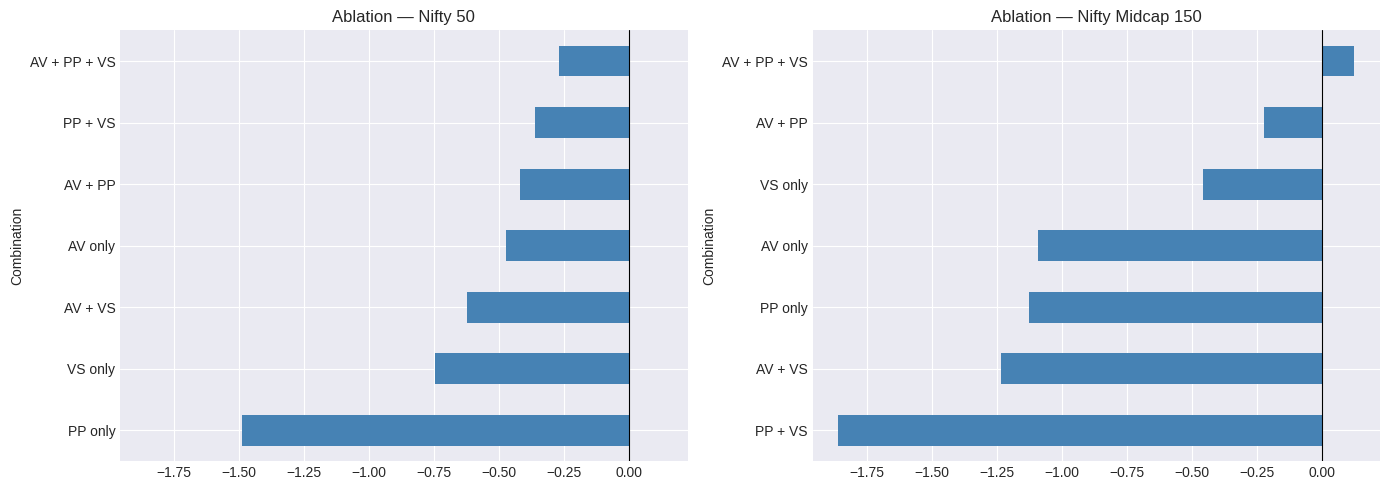

In [ ]:
fig, axes = plt.subplots(1, len(ablation_by_universe), figsize=(7 * len(ablation_by_universe), 5), sharex=True)
if len(ablation_by_universe) == 1:
    axes = [axes]
for ax, (name, res) in zip(axes, ablation_by_universe.items()):
    res["Sharpe Ratio"].sort_values().plot(kind="barh", ax=ax, color="steelblue")
    ax.set_title(f"Ablation — {name}")
    ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()


## 8. Weighted Linear Signal — Grid Search, Both Universes

`w1·Z(AV) + w2·Z(PP) + w3·Z(VS)`, simplex grid at 0.2 steps (21 combos), reported
per universe. Same caveat as before: this is an in-sample exploration pass on the
full period — Section 12's walk-forward is the leakage-free version of this same idea.

In [ ]:
def run_weight_search(panel_df, hold_days=DEFAULT_HOLD, cost_bps=COST_BPS, step=0.2):
    rows = []
    for w1, w2, w3 in weight_grid(step):
        p = panel_df.copy()
        p["_sig"] = weighted_signal(p, w1, w2, w3)
        pf = build_quintile_portfolio(p, "_sig", hold_days=hold_days, cost_bps=cost_bps)
        summary = performance_summary(pf, hold_days=hold_days)
        summary["w_AV"], summary["w_PP"], summary["w_VS"] = w1, w2, w3
        rows.append(summary)
    return pd.DataFrame(rows).sort_values("Sharpe Ratio", ascending=False).reset_index(drop=True)

weight_results_by_universe = {name: run_weight_search(p) for name, p in panels.items()}
best_weights_by_universe = {name: res.iloc[0][["w_AV", "w_PP", "w_VS"]]
                             for name, res in weight_results_by_universe.items()}

for name, res in weight_results_by_universe.items():
    bw = best_weights_by_universe[name]
    print(f"=== Best weights (in-sample) — {name}: AV={bw['w_AV']}, PP={bw['w_PP']}, VS={bw['w_VS']} ===")
    display(res.head(5)[["w_AV", "w_PP", "w_VS", "Annualized Return", "Sharpe Ratio", "Max Drawdown"]].round(4))
    print()


=== Best weights (in-sample) — Nifty 50: AV=0.6, PP=0.0, VS=0.4 ===


,w_AV,w_PP,w_VS,Annualized Return,Sharpe Ratio,Max Drawdown
0,0.6000,0.0000,0.4000,-0.0173,-0.2609,-0.2481
1,1.0000,0.0000,0.0000,-0.0286,-0.4714,-0.2489
2,0.8000,0.0000,0.2000,-0.0305,-0.4875,-0.2450
3,0.8000,0.2000,-0.0000,-0.0360,-0.5913,-0.2634
4,0.4000,0.2000,0.4000,-0.0458,-0.6651,-0.3046



=== Best weights (in-sample) — Nifty Midcap 150: AV=0.2, PP=0.0, VS=0.8 ===


,w_AV,w_PP,w_VS,Annualized Return,Sharpe Ratio,Max Drawdown
0,0.2000,0.0000,0.8000,-0.0190,-0.3521,-0.1489
1,0.0000,0.4000,0.6000,-0.0229,-0.4079,-0.1658
2,0.0000,0.2000,0.8000,-0.0223,-0.4182,-0.1785
3,0.0000,0.0000,1.0000,-0.0251,-0.4575,-0.1614
4,0.4000,0.0000,0.6000,-0.0274,-0.5063,-0.1650


## 9. Transaction Costs — Gross vs Net, Both Universes

Uses each universe's best in-sample weighted signal from Section 8, isolates the
cost impact (0 bps vs 20 bps).

In [ ]:
cost_comparison_by_universe = {}
for name, panel_u in panels.items():
    bw = best_weights_by_universe[name]
    p = panel_u.copy()
    p["_sig"] = weighted_signal(p, bw["w_AV"], bw["w_PP"], bw["w_VS"])
    pf_gross = build_quintile_portfolio(p, "_sig", cost_bps=0)
    pf_net   = build_quintile_portfolio(p, "_sig", cost_bps=COST_BPS)
    cost_comparison_by_universe[name] = pd.DataFrame({
        "Gross (no cost)": performance_summary(pf_gross, ret_col="GrossRet"),
        f"Net ({COST_BPS}bps/trade)": performance_summary(pf_net, ret_col="NetRet"),
    }).T

for name, res in cost_comparison_by_universe.items():
    print(f"=== Costs — {name} ===")
    display(res[["Annualized Return", "Sharpe Ratio", "Max Drawdown", "Hit Rate"]].round(4))
    print()


=== Costs — Nifty 50 ===


,Annualized Return,Sharpe Ratio,Max Drawdown,Hit Rate
Gross (no cost),0.0240,0.3612,-0.1465,0.4944
Net (20bps/trade),-0.0173,-0.2609,-0.2481,0.4647



=== Costs — Nifty Midcap 150 ===


,Annualized Return,Sharpe Ratio,Max Drawdown,Hit Rate
Gross (no cost),0.0220,0.4078,-0.0574,0.4981
Net (20bps/trade),-0.0190,-0.3521,-0.1489,0.4461


## 10. Holding-Period Sensitivity — Both Universes

1 / 3 / 5-day holds, each universe's best in-sample weighted signal, net of costs.

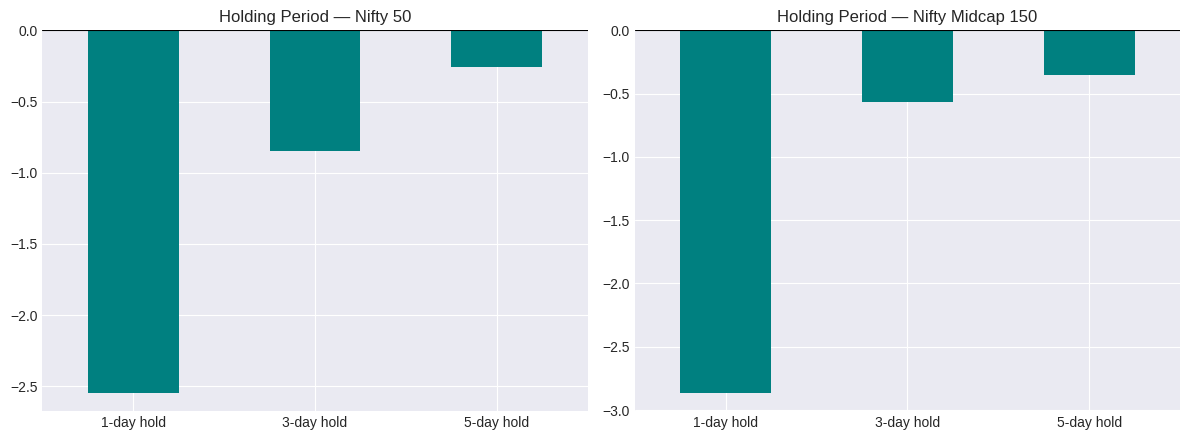

=== Holding period — Nifty 50 ===


,Annualized Return,Sharpe Ratio,Max Drawdown,Avg Turnover
1-day hold,-0.1743,-2.5466,-0.6567,0.4082
3-day hold,-0.0551,-0.8460,-0.3235,0.4082
5-day hold,-0.0173,-0.2609,-0.2481,0.4082



=== Holding period — Nifty Midcap 150 ===


,Annualized Return,Sharpe Ratio,Max Drawdown,Avg Turnover
1-day hold,-0.1642,-2.8651,-0.6276,0.4063
3-day hold,-0.0334,-0.5667,-0.2025,0.4063
5-day hold,-0.0190,-0.3521,-0.1489,0.4063


In [ ]:
hold_period_by_universe = {}
for name, panel_u in panels.items():
    bw = best_weights_by_universe[name]
    results = {}
    for h in HOLD_DAYS_LIST:
        p = panel_u.copy()
        p["_sig"] = weighted_signal(p, bw["w_AV"], bw["w_PP"], bw["w_VS"])
        pf = build_quintile_portfolio(p, "_sig", hold_days=h, cost_bps=COST_BPS)
        results[f"{h}-day hold"] = performance_summary(pf, hold_days=h)
    hold_period_by_universe[name] = pd.DataFrame(results).T

fig, axes = plt.subplots(1, len(hold_period_by_universe), figsize=(6 * len(hold_period_by_universe), 4.5))
if len(hold_period_by_universe) == 1:
    axes = [axes]
for ax, (name, res) in zip(axes, hold_period_by_universe.items()):
    res["Sharpe Ratio"].plot(kind="bar", ax=ax, color="teal")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"Holding Period — {name}")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

for name, res in hold_period_by_universe.items():
    print(f"=== Holding period — {name} ===")
    display(res[["Annualized Return", "Sharpe Ratio", "Max Drawdown", "Avg Turnover"]].round(4))
    print()


## 11. Passive Baselines — Buy-and-Hold, Both Universes

Nifty 50 also gets the actual index (`^NSEI`) as a second passive benchmark;
Midcap 150 uses equal-weight buy-and-hold of the universe only (no single clean
Yahoo Finance ticker for the Nifty Midcap 150 index itself — noted rather than
guessed at).

In [ ]:
def passive_summary(ret_series, periods_per_year=252):
    r = ret_series.dropna()
    if r.empty:
        return pd.Series({k: np.nan for k in [
            "Annualized Return", "Annualized Vol", "Sharpe Ratio", "Max Drawdown",
            "Hit Rate", "Profit Factor", "Avg Turnover", "N Rebalances"]})

    # Ensure r is a Series. If it's a DataFrame with one column, convert it to a Series.
    if isinstance(r, pd.DataFrame) and len(r.columns) == 1:
        r = r.iloc[:, 0]

    ann_ret = (1 + r).prod() ** (periods_per_year / len(r)) - 1
    ann_vol = r.std() * np.sqrt(periods_per_year)

    sharpe = ann_ret / ann_vol if ann_vol > 0 else np.nan
    equity = (1 + r).cumprod()
    max_dd = (equity / equity.cummax() - 1).min()
    return pd.Series({
        "Annualized Return": ann_ret, "Annualized Vol": ann_vol,
        "Sharpe Ratio": sharpe, "Max Drawdown": max_dd,
        "Hit Rate": (r > 0).mean(), "Profit Factor": np.nan,
        "Avg Turnover": 0.0, "N Rebalances": np.nan})

benchmark = yf.download(BENCHMARK, start=START_DATE, end=END_DATE, auto_adjust=False, progress=False)
benchmark = benchmark.rename(columns=str.title)
bh_index_ret = benchmark["Close"].pct_change().dropna()

passive_by_universe = {}
for name, panel_u in panels.items():
    bh_universe_ret = panel_u.groupby("Date")["Ret1"].mean().sort_index()
    entry = {f"Buy & Hold ({name}, equal-weight)": passive_summary(bh_universe_ret)}
    if name == "Nifty 50":
        entry["Buy & Hold (Nifty 50 Index)"] = passive_summary(bh_index_ret)
    passive_by_universe[name] = entry

## 12. Walk-Forward Evaluation + Baselines — Both Universes (the previously-missing piece)

This is Ryan's core ask, now run on **both** universes instead of only Nifty 50.
6 chronological folds, expanding window. For each test fold (folds 2–6):

- **Frozen 3-factor signal** (`AV×PP×VS`, zero fitted parameters — the original
  spec) and the two **baselines** (Momentum, Naive) need no fitting.
- **Adaptive weighted signal** — weights re-fit on training folds only, via the
  same grid as Section 8, then applied unchanged to the held-out fold. This is
  the leakage-free version of Section 8/9's in-sample search.

All strategies share identical cost (20bps) and horizon (5-day) assumptions.
OOS returns are stitched across the 5 test folds into one continuous series per
strategy before scoring.

In [ ]:
strategy_names = ["Frozen 3-Factor", "Adaptive Weighted (WF-fit)", "Momentum (20d)", "Naive Mean-Return"]

def fit_best_weights(train_panel, hold_days=DEFAULT_HOLD, cost_bps=COST_BPS):
    best_sharpe, best_w = -np.inf, (1.0, 0.0, 0.0)
    for w1, w2, w3 in weight_grid(0.2):
        sig = weighted_signal(train_panel, w1, w2, w3)
        pf = build_quintile_portfolio(train_panel.assign(_sig=sig), "_sig", hold_days=hold_days, cost_bps=cost_bps)
        s = performance_summary(pf, hold_days=hold_days)["Sharpe Ratio"]
        if pd.notna(s) and s > best_sharpe:
            best_sharpe, best_w = s, (w1, w2, w3)
    return best_w, best_sharpe


def walk_forward_evaluate(panel_df, hold_days=DEFAULT_HOLD, cost_bps=COST_BPS, n_folds=N_FOLDS):
    dates_sorted = sorted(panel_df["Date"].unique())
    fold_edges = np.array_split(dates_sorted, n_folds)

    oos_returns = {name: [] for name in strategy_names}
    fold_log = []

    for i in range(1, n_folds):
        train_dates = np.concatenate(fold_edges[:i])
        test_dates = fold_edges[i]
        assert train_dates.max() < test_dates.min(), "LEAKAGE: training window overlaps test window"

        train_panel = panel_df[panel_df["Date"].isin(train_dates)]
        test_panel = panel_df[panel_df["Date"].isin(test_dates)]

        best_w, train_sharpe = fit_best_weights(train_panel, hold_days, cost_bps)
        fold_log.append(dict(Fold=i + 1, TrainEnd=train_dates.max(), TestStart=test_dates.min(),
                              TestEnd=test_dates.max(), BestWeights=best_w, TrainSharpe=round(train_sharpe, 3)))

        configs = {
            "Frozen 3-Factor": SIGNAL_DEFS["AV + PP + VS"](test_panel),
            "Adaptive Weighted (WF-fit)": weighted_signal(test_panel, *best_w),
            "Momentum (20d)": momentum_signal(test_panel),
            "Naive Mean-Return": naive_signal(test_panel),
        }
        for name, sig in configs.items():
            pf = build_quintile_portfolio(test_panel.assign(_sig=sig), "_sig", hold_days=hold_days, cost_bps=cost_bps)
            if not pf.empty:
                oos_returns[name].append(pf["NetRet"])

    return oos_returns, pd.DataFrame(fold_log), fold_edges


walkforward_results = {}
fold_logs = {}
fold_edges_by_universe = {}

for name, panel_u in panels.items():
    print(f"Running walk-forward for {name}...")
    oos_returns, fold_log_df, fold_edges = walk_forward_evaluate(panel_u)
    walkforward_results[name] = oos_returns
    fold_logs[name] = fold_log_df
    fold_edges_by_universe[name] = fold_edges

for name, log in fold_logs.items():
    print(f"\n=== Walk-forward fold log — {name} ===")
    display(log)


Running walk-forward for Nifty 50...
Running walk-forward for Nifty Midcap 150...

=== Walk-forward fold log — Nifty 50 ===


,Fold,TrainEnd,TestStart,TestEnd,BestWeights,TrainSharpe
0,2,2022-01-13,2022-01-14,2022-12-12,"(1.0, 0.0, 0.0)",1.6090
1,3,2022-12-12,2022-12-13,2023-11-07,"(0.4, 0.6, 0.0)",-0.2920
2,4,2023-11-07,2023-11-08,2024-10-08,"(1.0, 0.0, 0.0)",-0.3100
3,5,2024-10-08,2024-10-09,2025-09-02,"(1.0, 0.0, 0.0)",-0.6090
4,6,2025-09-02,2025-09-03,2026-07-31,"(0.6, 0.0, 0.4)",-0.4280



=== Walk-forward fold log — Nifty Midcap 150 ===


,Fold,TrainEnd,TestStart,TestEnd,BestWeights,TrainSharpe
0,2,2022-01-13,2022-01-14,2022-12-12,"(0.0, 0.8, 0.2)",1.2420
1,3,2022-12-12,2022-12-13,2023-11-07,"(0.0, 0.2, 0.8)",-0.0630
2,4,2023-11-07,2023-11-08,2024-10-08,"(0.0, 0.2, 0.8)",-0.1260
3,5,2024-10-08,2024-10-09,2025-09-02,"(0.0, 0.2, 0.8)",0.0210
4,6,2025-09-02,2025-09-03,2026-07-31,"(0.0, 0.4, 0.6)",-0.0560


In [ ]:
final_comparison_by_universe = {}

for uni_name in panels:
    active_results = {}
    for strat_name in strategy_names:
        rets = walkforward_results[uni_name][strat_name]
        if rets:
            stitched = pd.concat(rets).sort_index()
            active_results[strat_name] = performance_summary(pd.DataFrame({"NetRet": stitched}))

    combined = pd.DataFrame({**active_results, **passive_by_universe[uni_name]}).T
    combined = combined.sort_values("Sharpe Ratio", ascending=False)
    final_comparison_by_universe[uni_name] = combined

    print(f"=== Final OOS comparison — {uni_name} ===")
    display(combined[["Annualized Return", "Sharpe Ratio", "Max Drawdown", "Hit Rate", "Avg Turnover"]].round(4))
    print()


=== Final OOS comparison — Nifty 50 ===


,Annualized Return,Sharpe Ratio,Max Drawdown,Hit Rate,Avg Turnover
"Buy & Hold (Nifty 50, equal-weight)",0.1561,1.1156,-0.1703,0.5624,0.0000
Buy & Hold (Nifty 50 Index),0.1066,0.7502,-0.1723,0.5338,0.0000
Frozen 3-Factor,-0.0010,-0.0193,-0.1528,0.4888,NaN
Naive Mean-Return,-0.0631,-0.8463,-0.3291,0.4664,NaN
Momentum (20d),-0.0681,-0.8971,-0.3172,0.4619,NaN
Adaptive Weighted (WF-fit),-0.0589,-1.0683,-0.2510,0.4170,NaN



=== Final OOS comparison — Nifty Midcap 150 ===


,Annualized Return,Sharpe Ratio,Max Drawdown,Hit Rate,Avg Turnover
"Buy & Hold (Nifty Midcap 150, equal-weight)",0.2844,1.6504,-0.2015,0.6055,0.0000
Naive Mean-Return,0.0075,0.1027,-0.1218,0.5471,NaN
Momentum (20d),-0.0319,-0.4638,-0.1649,0.5157,NaN
Frozen 3-Factor,-0.0325,-0.6897,-0.1453,0.4484,NaN
Adaptive Weighted (WF-fit),-0.0458,-0.8177,-0.1983,0.4439,NaN


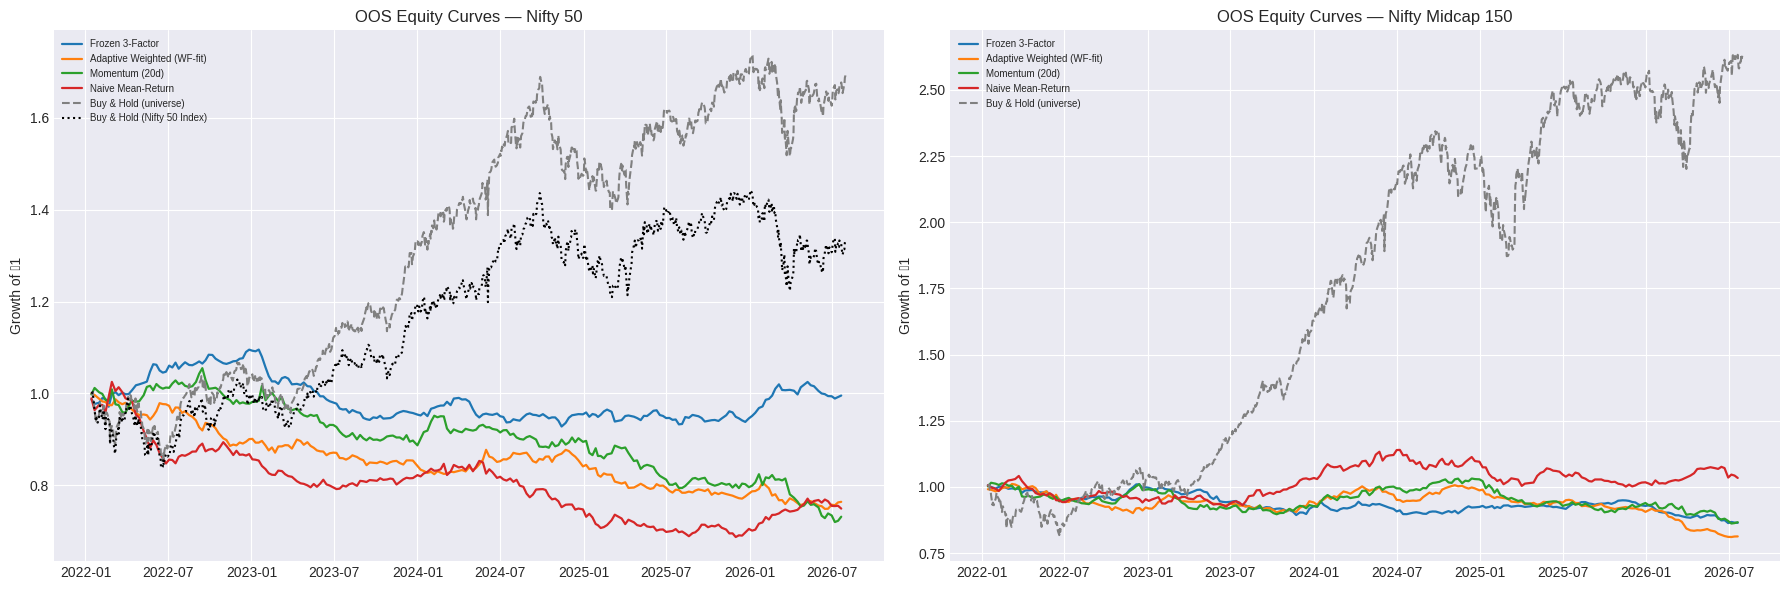

In [ ]:
fig, axes = plt.subplots(1, len(panels), figsize=(9 * len(panels), 6), sharey=False)
if len(panels) == 1:
    axes = [axes]

for ax, (uni_name, panel_u) in zip(axes, panels.items()):
    fold_edges = fold_edges_by_universe[uni_name]
    oos_start = fold_edges[1].min()

    for strat_name in strategy_names:
        rets = walkforward_results[uni_name][strat_name]
        if rets:
            stitched = pd.concat(rets).sort_index()
            equity = (1 + stitched).cumprod()
            ax.plot(equity.index, equity.values, label=f"{strat_name}", linewidth=1.6)

    bh_u = panel_u.groupby("Date")["Ret1"].mean().sort_index()
    bh_u = bh_u[bh_u.index >= oos_start]
    bh_u_equity = (1 + bh_u).cumprod()
    ax.plot(bh_u_equity.index, bh_u_equity.values, label="Buy & Hold (universe)", linestyle="--", color="gray")

    if uni_name == "Nifty 50":
        bh_i = bh_index_ret[bh_index_ret.index >= oos_start]
        bh_i_equity = (1 + bh_i).cumprod()
        ax.plot(bh_i_equity.index, bh_i_equity.values, label="Buy & Hold (Nifty 50 Index)", linestyle=":", color="black")

    ax.set_title(f"OOS Equity Curves — {uni_name}")
    ax.set_ylabel("Growth of ₹1")
    ax.legend(fontsize=7, loc="upper left")

plt.tight_layout()
plt.show()


## 13. Consolidated Verdict — Write-Up Guidance

Fill this against the actual tables above once run.

- **Ablation (Sec 7):** which combination wins in each universe? Does the
  ranking match between Nifty 50 and Midcap 150, or does the "best" component
  set change with liquidity?
- **Weighted vs multiplicative (Sec 8 vs Sec 7):** does linear weighting clearly
  beat the multiplicative form of the original spec, in either universe?
- **Costs (Sec 9):** in each universe, does net Sharpe stay close to gross, or
  get wiped out? Compare the gap between universes — Midcap should plausibly
  have higher real-world slippage than the flat 20bps assumed here, so treat
  its net numbers as optimistic, not conservative.
- **Holding period (Sec 10):** same horizon best in both universes, or does
  Midcap favor a different one?
- **Walk-forward + baselines (Sec 12) — the headline result:** for each
  universe, does *any* active strategy beat Buy & Hold out-of-sample, net of
  costs? Does the engineered signal beat plain Momentum? Does it clear the
  Naive Mean-Return floor? This table is the one to lead the write-up with —
  everything above it is exploratory support for how you got here.
- **Liquidity hypothesis (Research Question 4), now properly tested:** compare
  Section 12's OOS Sharpe between Nifty 50 and Midcap 150 directly. State
  plainly whether the data supports "inefficiencies are stronger in less liquid
  names" or contradicts it — either is a valid, gradeable finding as long as
  it's the one the numbers actually show.

**Suggested closing claim structure:** *"A price–volume proxy signal built from
OHLCV data shows [small/no] gross edge over a 5-day horizon in [universe(s)],
which [does/does not] survive realistic transaction costs and [does/does not]
outperform simple momentum or buy-and-hold benchmarks out-of-sample. The
[strongest/weakest] evidence for short-term inefficiency was found in
[Nifty 50 / Midcap 150]."* Fill the brackets from the tables — don't round up.


## 14. Extended Rigor — Newey-West Significance, Price-vs-Price+Volume Ablation, Reversal Check, Train/Val/Test Walk-Forward

Four additions that tighten the study without changing anything above:

1. **Newey-West (HAC) significance** on every strategy's out-of-sample return series — is the mean return actually distinguishable from zero once we account for autocorrelation from overlapping 5-day holding periods?
2. **The headline ablation, done out-of-sample**: Price-only (`PP + VS`) vs Price+Volume (`AV + PP + VS`), stitched across the same walk-forward test folds as Section 12 — not the in-sample Section 7 version.
3. **Naming the reversal/continuation signal explicitly**: `Z_PP` (Price Pressure) is the short-horizon reversal/continuation signal used throughout. Its correlation sign with forward returns tells us which regime it's in.
4. **A genuine train/validation/test split**: Section 12's `fit_best_weights` picks weights using the same training-fold Sharpe it reports — validation and fitting are the same data. Here, weights are chosen on a held-out validation slice carved out of the training window, and only then applied to the untouched test fold.

In [ ]:
!pip install statsmodels --quiet
import statsmodels.api as sm


### 14a. Newey-West significance check


In [ ]:
def newey_west_stats(ret_series, hold_days=DEFAULT_HOLD):
    """
    Tests whether a return series' mean is distinguishable from zero, using
    Newey-West HAC standard errors. This matters here specifically because a
    5-day hold creates overlapping return windows -> adjacent rebalance
    returns are mechanically autocorrelated, which understates plain OLS/t-test
    standard errors and can make noise look significant.
    Lag truncation: max(hold_days, floor(4*(T/100)**(2/9))) -- standard rule of thumb.
    """
    r = ret_series.dropna()
    if len(r) < 5:
        return pd.Series({"Mean Return/Trade": np.nan, "NW t-stat": np.nan,
                           "NW p-value": np.nan, "Lags": np.nan, "N": len(r)})
    lags = max(hold_days, int(np.floor(4 * (len(r) / 100) ** (2 / 9))))
    X = np.ones(len(r))
    model = sm.OLS(r.values, X).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return pd.Series({
        "Mean Return/Trade": model.params[0],
        "NW t-stat": model.tvalues[0],
        "NW p-value": model.pvalues[0],
        "Lags": lags,
        "N": len(r),
    })


print("=== Newey-West significance -- is each Section 12 strategy's mean OOS return distinguishable from zero? ===\n")
nw_by_universe = {}
for uni_name in panels:
    rows = {}
    for strat_name in strategy_names:
        rets = walkforward_results[uni_name][strat_name]
        if rets:
            stitched = pd.concat(rets).sort_index()
            rows[strat_name] = newey_west_stats(stitched, hold_days=DEFAULT_HOLD)

    fold_edges = fold_edges_by_universe[uni_name]
    oos_start = fold_edges[1].min()
    bh_ret = panels[uni_name].groupby("Date")["Ret1"].mean().sort_index()
    bh_oos = bh_ret[bh_ret.index >= oos_start]
    rows[f"Buy & Hold ({uni_name}, equal-weight)"] = newey_west_stats(bh_oos, hold_days=1)

    nw_df = pd.DataFrame(rows).T.sort_values("NW t-stat", ascending=False)
    nw_df["Significant (|t|>1.96)"] = nw_df["NW t-stat"].abs() > 1.96
    nw_by_universe[uni_name] = nw_df
    print(f"--- {uni_name} ---")
    display(nw_df.round(4))
    print()


=== Newey-West significance -- is each Section 12 strategy's mean OOS return distinguishable from zero? ===

--- Nifty 50 ---


,Mean Return/Trade,NW t-stat,NW p-value,Lags,N,Significant (|t|>1.96)
"Buy & Hold (Nifty 50, equal-weight)",0.0005,1.9966,0.0459,6.0000,"1,121.0000",True
Frozen 3-Factor,0.0000,0.0127,0.9899,5.0000,223.0000,False
Naive Mean-Return,-0.0012,-1.6501,0.0989,5.0000,223.0000,False
Momentum (20d),-0.0013,-2.0543,0.0399,5.0000,223.0000,True
Adaptive Weighted (WF-fit),-0.0012,-2.3673,0.0179,5.0000,223.0000,True



--- Nifty Midcap 150 ---


,Mean Return/Trade,NW t-stat,NW p-value,Lags,N,Significant (|t|>1.96)
"Buy & Hold (Nifty Midcap 150, equal-weight)",0.0009,2.6711,0.0076,6.0000,"1,121.0000",True
Naive Mean-Return,0.0002,0.2848,0.7758,5.0000,223.0000,False
Momentum (20d),-0.0006,-0.9366,0.3490,5.0000,223.0000,False
Frozen 3-Factor,-0.0006,-1.3367,0.1813,5.0000,223.0000,False
Adaptive Weighted (WF-fit),-0.0009,-1.5417,0.1231,5.0000,223.0000,False


### 14b. Key ablation, out-of-sample: does volume (AV) add value beyond price alone (PP+VS)?

Same question as Section 7's ablation, but stitched across the Section 12 walk-forward test folds instead of computed in-sample on the full period -- this is the version that should actually be trusted and quoted.


In [ ]:
def stitch_signal_oos(panel_df, signal_fn, fold_edges, hold_days=DEFAULT_HOLD, cost_bps=COST_BPS):
    rets = []
    for i in range(1, len(fold_edges)):
        test_panel = panel_df[panel_df["Date"].isin(fold_edges[i])]
        sig = signal_fn(test_panel)
        pf = build_quintile_portfolio(test_panel.assign(_sig=sig), "_sig", hold_days=hold_days, cost_bps=cost_bps)
        if not pf.empty:
            rets.append(pf["NetRet"])
    return pd.concat(rets).sort_index() if rets else pd.Series(dtype=float)


print("=== Price-only (PP+VS) vs Price+Volume (AV+PP+VS) -- out-of-sample ===\n")
price_vol_ablation = {}
for uni_name, panel_u in panels.items():
    fold_edges = fold_edges_by_universe[uni_name]
    price_only_ret = stitch_signal_oos(panel_u, SIGNAL_DEFS["PP + VS"], fold_edges)
    price_vol_ret   = stitch_signal_oos(panel_u, SIGNAL_DEFS["AV + PP + VS"], fold_edges)

    summary = pd.DataFrame({
        "Price-only (PP+VS)": performance_summary(pd.DataFrame({"NetRet": price_only_ret})),
        "Price+Volume (AV+PP+VS)": performance_summary(pd.DataFrame({"NetRet": price_vol_ret})),
    }).T
    nw_summary = pd.DataFrame({
        "Price-only (PP+VS)": newey_west_stats(price_only_ret),
        "Price+Volume (AV+PP+VS)": newey_west_stats(price_vol_ret),
    }).T
    combined = summary.join(nw_summary[["Mean Return/Trade", "NW t-stat", "NW p-value"]])
    price_vol_ablation[uni_name] = combined
    print(f"--- {uni_name} ---")
    display(combined[["Annualized Return", "Sharpe Ratio", "Mean Return/Trade", "NW t-stat", "NW p-value"]].round(4))
    print()


=== Price-only (PP+VS) vs Price+Volume (AV+PP+VS) -- out-of-sample ===

--- Nifty 50 ---


,Annualized Return,Sharpe Ratio,Mean Return/Trade,NW t-stat,NW p-value
Price-only (PP+VS),-0.0801,-1.5114,-0.0016,-3.7105,0.0002
Price+Volume (AV+PP+VS),-0.0010,-0.0193,0.0000,0.0127,0.9899



--- Nifty Midcap 150 ---


,Annualized Return,Sharpe Ratio,Mean Return/Trade,NW t-stat,NW p-value
Price-only (PP+VS),-0.0976,-2.3085,-0.0020,-5.6034,0.0000
Price+Volume (AV+PP+VS),-0.0325,-0.6897,-0.0006,-1.3367,0.1813


### 14c. Short-horizon reversal/continuation check

`Z_PP` (Price Pressure -- where the close sits in the day's high-low range, cross-sectionally z-scored) is the study's short-horizon reversal/continuation signal. Its correlation sign against forward returns tells us which regime dominates: positive correlation means high price pressure today keeps going (continuation); negative means it tends to mean-revert (reversal).


In [ ]:
print(f"=== Z_PP vs FwdRet_{DEFAULT_HOLD}: reversal or continuation? ===\n")
reversal_check = {}
for uni_name, panel_u in panels.items():
    sub = panel_u[["Z_PP", f"FwdRet_{DEFAULT_HOLD}"]].dropna()
    corr = sub.corr().iloc[0, 1]
    direction = "continuation (positive PP tends to keep moving up)" if corr > 0 \
                else "reversal (positive PP tends to mean-revert)"
    reversal_check[uni_name] = corr
    print(f"{uni_name}: corr(Z_PP, FwdRet_{DEFAULT_HOLD}) = {corr:.4f}  ->  signal behaves like {direction}, n={len(sub)}")


=== Z_PP vs FwdRet_5: reversal or continuation? ===

Nifty 50: corr(Z_PP, FwdRet_5) = -0.0062  ->  signal behaves like reversal (positive PP tends to mean-revert), n=65652
Nifty Midcap 150: corr(Z_PP, FwdRet_5) = -0.0065  ->  signal behaves like reversal (positive PP tends to mean-revert), n=179586


### 14d. Chronological Train / Validation / Test walk-forward

Section 12's `fit_best_weights` selects weights using the training fold's own Sharpe -- the fold that picks the weights is the same fold used to judge them, which is a softer form of the in-sample leakage this whole study is trying to avoid. Here, each expanding training window is itself split chronologically into a **fit** slice (unused for selection, kept for symmetry with a real trading pipeline) and a **validation** slice used purely to score candidate weight combinations. Weights are chosen on validation only, then applied unchanged to the fully held-out test fold -- test data is never touched until the single final scoring pass.


In [ ]:
def fit_best_weights_on_validation(val_panel, hold_days=DEFAULT_HOLD, cost_bps=COST_BPS):
    best_sharpe, best_w = -np.inf, (1.0, 0.0, 0.0)
    for w1, w2, w3 in weight_grid(0.2):
        sig = weighted_signal(val_panel, w1, w2, w3)
        pf = build_quintile_portfolio(val_panel.assign(_sig=sig), "_sig", hold_days=hold_days, cost_bps=cost_bps)
        s = performance_summary(pf, hold_days=hold_days)["Sharpe Ratio"]
        if pd.notna(s) and s > best_sharpe:
            best_sharpe, best_w = s, (w1, w2, w3)
    return best_w, best_sharpe


def walk_forward_evaluate_3way(panel_df, hold_days=DEFAULT_HOLD, cost_bps=COST_BPS,
                                n_folds=N_FOLDS, val_frac=0.2):
    dates_sorted = sorted(panel_df["Date"].unique())
    fold_edges = np.array_split(dates_sorted, n_folds)

    oos_returns = []
    fold_log = []

    for i in range(1, n_folds):
        all_train_dates = np.concatenate(fold_edges[:i])
        test_dates = fold_edges[i]
        assert all_train_dates.max() < test_dates.min(), "LEAKAGE: training window overlaps test window"

        split_idx = int(len(all_train_dates) * (1 - val_frac))
        split_idx = max(1, min(split_idx, len(all_train_dates) - 1))
        fit_dates, val_dates = all_train_dates[:split_idx], all_train_dates[split_idx:]
        assert fit_dates.max() < val_dates.min() < test_dates.min(), "LEAKAGE: fit/val/test overlap"

        val_panel = panel_df[panel_df["Date"].isin(val_dates)]
        test_panel = panel_df[panel_df["Date"].isin(test_dates)]

        best_w, val_sharpe = fit_best_weights_on_validation(val_panel, hold_days, cost_bps)
        fold_log.append(dict(Fold=i + 1, FitEnd=fit_dates.max(), ValStart=val_dates.min(),
                              ValEnd=val_dates.max(), TestStart=test_dates.min(), TestEnd=test_dates.max(),
                              BestWeights=best_w, ValSharpe=round(val_sharpe, 3) if pd.notna(val_sharpe) else np.nan))

        sig = weighted_signal(test_panel, *best_w)
        pf = build_quintile_portfolio(test_panel.assign(_sig=sig), "_sig", hold_days=hold_days, cost_bps=cost_bps)
        if not pf.empty:
            oos_returns.append(pf["NetRet"])

    return oos_returns, pd.DataFrame(fold_log)


print("=== Train/Validation/Test walk-forward (weights chosen on validation, never on test) ===\n")
threeway_results, threeway_logs, threeway_perf = {}, {}, {}
for uni_name, panel_u in panels.items():
    oos_returns, fold_log_df = walk_forward_evaluate_3way(panel_u)
    threeway_results[uni_name] = oos_returns
    threeway_logs[uni_name] = fold_log_df
    print(f"--- {uni_name}: fold log ---")
    display(fold_log_df)

    stitched = pd.concat(oos_returns).sort_index() if oos_returns else pd.Series(dtype=float)
    perf = performance_summary(pd.DataFrame({"NetRet": stitched}))
    nw = newey_west_stats(stitched)
    combined = pd.concat([perf, nw[["Mean Return/Trade", "NW t-stat", "NW p-value"]]])
    threeway_perf[uni_name] = combined
    print(f"--- {uni_name}: OOS performance, weights fit on validation only (never on test) ---")
    display(combined.round(4))
    print()


=== Train/Validation/Test walk-forward (weights chosen on validation, never on test) ===

--- Nifty 50: fold log ---


,Fold,FitEnd,ValStart,ValEnd,TestStart,TestEnd,BestWeights,ValSharpe
0,2,2021-11-10,2021-11-11,2022-01-13,2022-01-14,2022-12-12,"(1.0, 0.0, 0.0)",0.7740
1,3,2022-07-29,2022-08-01,2022-12-12,2022-12-13,2023-11-07,"(0.0, 0.0, 1.0)",-0.5220
2,4,2023-04-24,2023-04-25,2023-11-07,2023-11-08,2024-10-08,"(0.0, 1.0, 0.0)",-0.8350
3,5,2024-01-11,2024-01-12,2024-10-08,2024-10-09,2025-09-02,"(0.2, 0.0, 0.8)",3.4590
4,6,2024-10-07,2024-10-08,2025-09-02,2025-09-03,2026-07-31,"(0.4, 0.0, 0.6)",-0.7890


--- Nifty 50: OOS performance, weights fit on validation only (never on test) ---


,0
Annualized Return,-0.1036
Annualized Vol,0.0594
Sharpe Ratio,-1.7430
Max Drawdown,-0.3984
Hit Rate,0.3408
Profit Factor,0.5191
Avg Turnover,NaN
N Rebalances,223.0000
Mean Return/Trade,-0.0021
NW t-stat,-4.1861



--- Nifty Midcap 150: fold log ---


,Fold,FitEnd,ValStart,ValEnd,TestStart,TestEnd,BestWeights,ValSharpe
0,2,2021-11-10,2021-11-11,2022-01-13,2022-01-14,2022-12-12,"(0.0, 0.0, 1.0)",2.6240
1,3,2022-07-29,2022-08-01,2022-12-12,2022-12-13,2023-11-07,"(0.0, 0.0, 1.0)",1.3850
2,4,2023-04-24,2023-04-25,2023-11-07,2023-11-08,2024-10-08,"(0.4, 0.2, 0.4)",-0.9140
3,5,2024-01-11,2024-01-12,2024-10-08,2024-10-09,2025-09-02,"(0.0, 0.6, 0.4)",2.3640
4,6,2024-10-07,2024-10-08,2025-09-02,2025-09-03,2026-07-31,"(0.0, 0.0, 1.0)",-0.9320


--- Nifty Midcap 150: OOS performance, weights fit on validation only (never on test) ---


,0
Annualized Return,-0.0502
Annualized Vol,0.0534
Sharpe Ratio,-0.9408
Max Drawdown,-0.2440
Hit Rate,0.4215
Profit Factor,0.7106
Avg Turnover,NaN
N Rebalances,223.0000
Mean Return/Trade,-0.0010
NW t-stat,-1.7389


### 14e. Updated verdict, incorporating significance

Fill against the actual Section 14 tables once run:

- **Significance (14a):** for each strategy, is `|NW t-stat| > 1.96`? A negative Sharpe that *isn't* significantly different from zero is a weaker claim than one that is -- say so explicitly rather than treating every negative number as proven harm.
- **Volume's incremental value (14b):** compare Price-only vs Price+Volume Sharpe **and** NW t-stat, out-of-sample, in both universes. If AV doesn't measurably improve on PP+VS after this correction, that's the cleanest one-line answer to "does volume help."
- **Reversal vs continuation (14c):** state the sign plainly -- it tells the reader what kind of inefficiency (if any) `Z_PP` is proxying for.
- **Train/Val/Test (14d) vs Section 12:** does the validation-selected weight walk-forward result differ materially from Section 12's train-selected version? If it's similar (or worse), that reinforces the conclusion that the earlier fitting procedure wasn't finding genuine signal either.
- **Closing claim, updated:** *"A price-volume proxy signal shows [no/marginal] out-of-sample edge over a 5-day horizon that is [not] statistically distinguishable from zero at conventional significance once autocorrelation from overlapping holds is accounted for; buy-and-hold remains the stronger risk-adjusted choice in both universes tested."* Fill from the actual numbers -- don't round up.
